# LDA: Kategorisasi Tema Berita Geopolitik

Notebook ini menjalankan dan menginspeksi topic modeling LDA dari modul proyek. LDA menghasilkan **distribusi probabilitas topik**, bukan label tema yang sudah diketahui. Nama tema perlu ditafsirkan manusia dari kata kunci dan contoh artikel.

Vocabulary dan model LDA di-fit pada artikel train saja. Nilai K dipilih dari coherence UMass pada train (default kandidat 8, 10, 12, 15); validation/test hanya ditransformasi dan digunakan untuk evaluasi prediksi setelah K dipilih.

Untuk Colab: buka notebook ini, jalankan setup. Jika data tidak ikut tersedia dari clone, unggah/copy `articles_aligned.csv`, `articles_split.csv`, dan `model_dataset.csv` ke path proyek yang ditampilkan atau ubah path di konfigurasi. Eksekusi eksperimen dapat memerlukan beberapa menit.

In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

IS_COLAB = "COLAB_RELEASE_TAG" in os.environ
REPOSITORY_URL = "https://github.com/mikailachmad/nlp-trio-bertiga.git"
if IS_COLAB:
    PROJECT_ROOT = Path('/content/nlp-trio-bertiga')
    if not (PROJECT_ROOT / '.git').exists():
        subprocess.run(['git', 'clone', REPOSITORY_URL, str(PROJECT_ROOT)], check=True)
else:
    PROJECT_ROOT = next(
        (path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (path / 'src' / 'models').is_dir()),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Jalankan notebook dari dalam folder repository proyek.')

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print('Project root:', PROJECT_ROOT)
print('Runtime:', 'Google Colab' if IS_COLAB else 'lokal')

Project root: /home/ajipratama53/Projects/nlp-trio-bertiga
Runtime: lokal


In [2]:
IMPORT_TO_PACKAGE = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'sklearn': 'scikit-learn',
    'xgboost': 'xgboost',
    'scipy': 'scipy',
}
missing = [pkg for module, pkg in IMPORT_TO_PACKAGE.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

ARTICLES_PATH = PROJECT_ROOT / 'data/processed/articles_aligned.csv'
ARTICLE_SPLITS_PATH = PROJECT_ROOT / 'data/split/articles_split.csv'
MODEL_DATASET_PATH = PROJECT_ROOT / 'data/feature_extracted/model_dataset.csv'
missing_files = [path for path in (ARTICLES_PATH, ARTICLE_SPLITS_PATH, MODEL_DATASET_PATH)
                 if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        'Data proyek belum tersedia. Unggah/salin file berikut ke path proyek atau '
        'ubah konfigurasi path:\n' + '\n'.join(map(str, missing_files))
    )
print('Input data tersedia.')

Input data tersedia.


## Konfigurasi dan jalankan eksperimen

Agar inspeksi topik dilakukan sebelum melihat metrik validation/test, jalankan dua tahap: (1) `RUN_TOPIC_SELECTION=True` menghasilkan coherence dan kata kunci kandidat dari train saja lalu berhenti; (2) inspeksi hasil dan isi `SELECTED_K`, kemudian set `RUN_EXPERIMENT=True` untuk ekstraksi/evaluasi. Kedua flag default `False` agar notebook dapat membaca artefak yang sudah tersedia.

In [3]:
OUTPUT_PREFIX = '10_lda_topics'
FEATURE_DIR = PROJECT_ROOT / 'data/feature_extracted'
RESULTS_DIR = PROJECT_ROOT / 'results'
MODEL_PATH = PROJECT_ROOT / 'data/features/artifacts/lda_geopolitical_topics.joblib'
TOPIC_COUNTS = '8,10,12,15'
SELECTED_K = 8  # Ganti setelah memeriksa coherence dan kata kunci kandidat.
RUN_TOPIC_SELECTION = False
RUN_EXPERIMENT = False

COMMON_ARGS = [
        sys.executable, '-m', 'src.models.lda_nlp_only',
        '--articles', str(ARTICLES_PATH),
        '--article-splits', str(ARTICLE_SPLITS_PATH),
        '--model-dataset', str(MODEL_DATASET_PATH),
        '--feature-dir', str(FEATURE_DIR),
        '--results-dir', str(RESULTS_DIR),
        '--model-path', str(MODEL_PATH),
        '--output-prefix', OUTPUT_PREFIX,
    ]
if RUN_TOPIC_SELECTION:
    subprocess.run(
        [*COMMON_ARGS, '--topic-counts', TOPIC_COUNTS, '--select-topics-only'],
        cwd=PROJECT_ROOT, check=True,
    )
if RUN_EXPERIMENT:
    if SELECTED_K is None or SELECTED_K < 2:
        raise ValueError('Pilih SELECTED_K >= 2 setelah inspeksi kandidat.')
    subprocess.run(
        [*COMMON_ARGS, '--n-topics', str(SELECTED_K)],
        cwd=PROJECT_ROOT, check=True,
    )
if not RUN_TOPIC_SELECTION and not RUN_EXPERIMENT:
    print('Eksekusi dilewati; notebook akan memuat artefak yang sudah tersedia.')

Eksekusi dilewati; notebook akan memuat artefak yang sudah tersedia.


## Bandingkan coherence dan kata kunci topik

UMass coherence membantu membandingkan kandidat K pada **train saja**; skor bukan jaminan bahwa topik otomatis sesuai kategori geopolitik. Inspeksi kata kunci dan contoh artikel diperlukan sebelum memberi nama tema.

In [4]:
import pandas as pd
from IPython.display import display

candidate_path = RESULTS_DIR / f'{OUTPUT_PREFIX}_topic_counts.csv'
terms_path = RESULTS_DIR / f'{OUTPUT_PREFIX}_topic_terms.csv'
article_topics_path = FEATURE_DIR / f'{OUTPUT_PREFIX}_article_topics.csv'
daily_topics_path = FEATURE_DIR / f'{OUTPUT_PREFIX}_daily_features.csv'
comparison_path = RESULTS_DIR / f'{OUTPUT_PREFIX}_comparison.csv'
results_path = RESULTS_DIR / f'{OUTPUT_PREFIX}_results.json'
if candidate_path.is_file():
    candidate_scores = pd.read_csv(candidate_path)
    display(candidate_scores[['n_topics', 'umass_coherence', 'top_terms']])
    print('Pilih K berdasarkan coherence train, kata kunci dan pemahaman domain; jangan memilih berdasarkan hasil test.')
else:
    print('Belum ada sweep kandidat. Set RUN_TOPIC_SELECTION=True dan jalankan sel konfigurasi.')

final_outputs = [terms_path, article_topics_path, daily_topics_path,
                 comparison_path, results_path]
if all(path.is_file() for path in final_outputs):
    topic_terms = pd.read_csv(terms_path)
    article_topics = pd.read_csv(article_topics_path, parse_dates=['trading_date'])
    daily_topics = pd.read_csv(daily_topics_path, parse_dates=['date'])
    comparison = pd.read_csv(comparison_path)
    display(topic_terms)
else:
    print('Model final belum dijalankan; setelah memilih K, set RUN_EXPERIMENT=True.')

,n_topics,umass_coherence,top_terms
0,8,-0.793760,['oil | prices | energy | year | gas | supply ...
1,12,-0.817860,['energy | year | gas | billion | company | pr...
2,10,-0.851548,['year | energy | billion | prices | gas | com...
3,15,-0.893407,['energy | gas | oil | prices | climate | fuel...


Pilih K berdasarkan coherence train, kata kunci dan pemahaman domain; jangan memilih berdasarkan hasil test.


,topic_id,top_terms
0,1,oil | prices | energy | year | gas | supply | ...
1,2,china | us | trump | chinese | trade | india |...
2,3,sea | us | saudi | iran | turkey | red | uae |...
3,4,israel | gaza | hamas | israeli | war | iran |...
4,5,company | companies | us | cnbc | new | busine...
5,6,year | inflation | bank | economy | us | marke...
6,7,ukraine | russia | russian | military | war | ...
7,8,russia | ukraine | russian | putin | president...


In [5]:
import re
if 'article_topics' in globals():
    topic_columns = [column for column in article_topics if re.fullmatch(r'topic_\d+', column)]
    train_articles = article_topics[article_topics['split'].eq('train')]
    representatives = []
    for topic_id in range(1, len(topic_columns) + 1):
        sample = (train_articles[train_articles['dominant_topic'].eq(topic_id)]
                  .nlargest(3, 'topic_confidence'))
        for row in sample.itertuples(index=False):
            representatives.append({
                'topic_id': topic_id,
                'confidence': round(float(row.topic_confidence), 3),
                'title': row.title,
                'url': row.url,
            })
    display(pd.DataFrame(representatives))
else:
    print('Contoh artikel tersedia setelah model final dijalankan.')

# Isi setelah inspeksi kata kunci + contoh judul; label ini interpretasi manual.
TOPIC_LABELS = {
    # 1: 'Energi dan komoditas',
}
if TOPIC_LABELS and 'topic_terms' in globals():
    topic_terms['human_label'] = topic_terms['topic_id'].map(TOPIC_LABELS)
    display(topic_terms)

,topic_id,confidence,title,url
0,1,0.998,gasoline gallon summer causing pain consumers,https://www.cnbc.com/2022/05/18/gasoline-could...
1,1,0.998,mcdonald revenue tops estimates fueled price h...,https://www.cnbc.com/2022/04/28/mcdonalds-mcd-...
2,1,0.996,yum brands earnings miss estimates kfc pizza h...,https://www.cnbc.com/2024/11/05/yum-brands-yum...
3,2,0.998,blinken meets chinese foreign minister qin gan...,https://www.cnbc.com/2023/06/18/blinken-meets-...
4,2,0.997,china presses us cancel tariffs test bilateral...,https://www.cnbc.com/2021/10/09/us-china-trade...
5,2,0.996,trump signs sweeping reciprocal tariff plan sa...,https://www.cnbc.com/2025/02/13/trump-reciproc...
6,3,0.984,shipping giant maersk prepares resume operatio...,https://www.cnbc.com/2023/12/24/shipping-giant...
7,3,0.914,us launches operation prosperity guardian defe...,https://www.cnbc.com/2023/12/18/us-to-expand-r...
8,3,0.900,uk us sanction senior houthis red sea shipping...,https://www.cnbc.com/2024/01/25/uk-and-us-sanc...
9,4,0.998,israel vows mighty vengeance deadliest day yea...,https://www.cnbc.com/2023/10/07/israel-declare...


## Distribusi topik harian dan evaluasi prediksi

Fitur per hari adalah rata-rata probabilitas topik artikel pada hari trading tersebut; tiap artikel berbobot sama. Hari tanpa artikel mempunyai semua probabilitas topik nol. Tabel berikut membandingkan baseline NLP yang sudah ada dengan baseline + fitur LDA pada validation dan test.

split,test,train,val
topic_001,0.155178,0.094406,0.110714
topic_002,0.140732,0.110354,0.251486
topic_003,0.089372,0.052182,0.025030
topic_004,0.085973,0.099859,0.043405
topic_005,0.121102,0.136604,0.156517
topic_006,0.263718,0.117139,0.222158
topic_007,0.033414,0.127257,0.031610
topic_008,0.071406,0.124474,0.074334


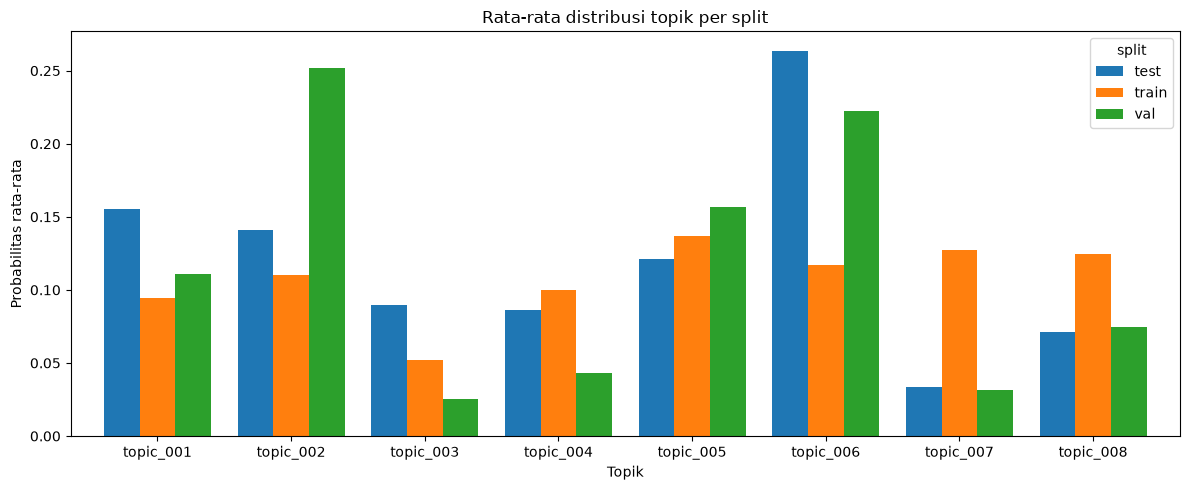

,model,split,task,accuracy,balanced_accuracy,macro_f1,kappa,rmse,mae,mape,skill_vs_naive,directional_hit
6,Baseline NLP,val,clf,0.3333,0.3456,0.3334,0.0157,NaN,NaN,NaN,NaN,NaN
7,Baseline NLP,test,clf,0.2961,0.3292,0.2856,-0.0095,NaN,NaN,NaN,NaN,NaN
8,Baseline NLP,val,reg,NaN,NaN,NaN,NaN,55.8495,41.0800,0.2492,0.0029,0.5085
9,Baseline NLP,test,reg,NaN,NaN,NaN,NaN,50.7325,37.8720,0.2174,0.0076,0.5978
10,Baseline NLP + LDA topics,val,clf,0.3729,0.3709,0.3709,0.0592,NaN,NaN,NaN,NaN,NaN
11,Baseline NLP + LDA topics,test,clf,0.2905,0.3054,0.2911,-0.0456,NaN,NaN,NaN,NaN,NaN
12,Baseline NLP + LDA topics,val,reg,NaN,NaN,NaN,NaN,55.6648,40.6438,0.2466,0.0062,0.5367
13,Baseline NLP + LDA topics,test,reg,NaN,NaN,NaN,NaN,50.9737,38.1819,0.2192,0.0029,0.5419


K terpilih: 8
Jumlah artikel dengan distribusi topik: {'train': 2431, 'val': 1007, 'test': 1070}
Jumlah hari no-news: {'train': 115, 'val': 15, 'test': 7}


In [6]:
import json
import matplotlib.pyplot as plt

if 'daily_topics' in globals():
    topic_columns = [column for column in daily_topics if re.fullmatch(r'topic_\d+', column)]
    display(daily_topics.groupby('split')[topic_columns].mean().T)
    ax = daily_topics.groupby('split')[topic_columns].mean().T.plot(
        kind='bar', figsize=(12, 5), width=0.8
    )
    ax.set_title('Rata-rata distribusi topik per split')
    ax.set_xlabel('Topik')
    ax.set_ylabel('Probabilitas rata-rata')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    metrics = comparison[
        comparison['model'].isin(['Baseline NLP', 'Baseline NLP + LDA topics'])
        & comparison['split'].isin(['val', 'test'])
    ]
    display(metrics)
    summary = json.loads(results_path.read_text(encoding='utf-8'))
    print('K terpilih:', summary['topic_model']['n_topics'])
    print('Jumlah artikel dengan distribusi topik:', summary['topic_model']['articles_with_topic_distribution'])
    print('Jumlah hari no-news:', summary['topic_model']['no_news_days'])
else:
    print('Eksekusi analisis hasil tersedia setelah eksperimen final berjalan.')